In [1]:
import torch
import torch.nn as nn

import numpy as np
from sklearn import metrics

import random
import copy

from torch.utils.data import DataLoader
from torchvision import transforms

from medmnist import PneumoniaMNIST

import matplotlib.pyplot as plt

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [3]:
# transform = transforms.ToTensor()

# Normalizing each pixel, after calculating the mean and standard deviation
# Calculation have been done before normalization
# To check the raw data, uncomment the first line and comment the transform line below
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.5716654658317566], [0.1761743128299713])
])

train_dataset = PneumoniaMNIST(
    split="train",
    transform=transform,
    download=True,
    size=128
)

val_dataset = PneumoniaMNIST(
    split="val",
    transform=transform,
    download=True,
    size=128
)

test_dataset = PneumoniaMNIST(
    split="test",
    transform=transform,
    download=True,
    size=128
)


In [4]:
int(np.sum(train_dataset.labels.squeeze() == 0))

1214

Training set size   : 4708
Validation set size : 524
Testing set size    : 624
-----------------------------------------
Training set data anaysis:
(Since the CNN model will be trained on the training set)
maximum/minimum heights:            (128, 128)
maximum/minimum width:              (128, 128)
number of images labeled 'normal':    1214
number of images labeled 'pneumonia': 3494
mean of every pixel: 8.91187482920941e-07 || standard deviation of every pixel: 0.9999964237213135


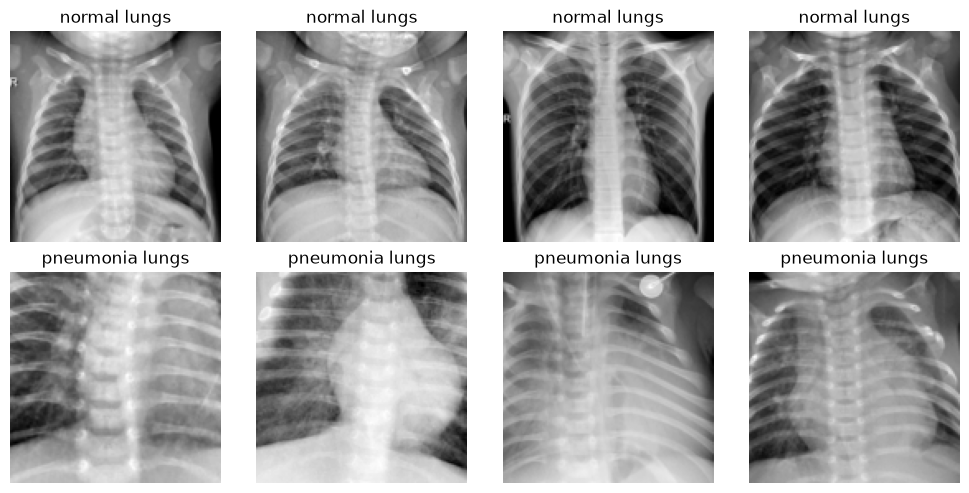

In [5]:
# Basic data analysis

print(f'Training set size   : {len(train_dataset)}')
print(f'Validation set size : {len(val_dataset)}')
print(f'Testing set size    : {len(test_dataset)}')
print('-----------------------------------------')
print('Training set data anaysis:')
print('(Since the CNN model will be trained on the training set)')

max_height, min_height, max_width, min_width = 0, 9999, 0, 999
zeros_count, ones_count = 0, 0

for image, index in train_dataset:
    if image.shape[1]>max_height:
        max_height = image.shape[1]
    if image.shape[1]<min_height:
        min_height = image.shape[1]
    if image.shape[2]>max_width:
        max_width = image.shape[2]
    if image.shape[2]<min_width:
        min_width = image.shape[2]

zeros_count = int(np.sum(train_dataset.labels.squeeze() == 0))
ones_count = int(np.sum(train_dataset.labels.squeeze() == 1))

print(f'maximum/minimum heights:            {max_height, min_height}')
print(f'maximum/minimum width:              {max_width, min_width}')
print(f'number of images labeled \'normal\':    {zeros_count}')
print(f'number of images labeled \'pneumonia\': {ones_count}')

rand_nor = random.sample([image for image, idx in train_dataset if idx == 0], 4)
rand_pne = random.sample([image for image, idx in train_dataset if idx == 1], 4)

# calculating the mean and standard deviation, for analysis and to use to normalize the images
sum_pixels = 0
sum_pixels_squared = 0

for i, _ in train_dataset:
    sum_pixels += i.sum()
    sum_pixels_squared += (i**2).sum()

total_pixels = len(train_dataset)*128*128

mean = sum_pixels/total_pixels
variance = (sum_pixels_squared/total_pixels)-(mean**2) #Konig-huygens formula
std = torch.sqrt(variance)

print(f'mean of every pixel: {mean} || standard deviation of every pixel: {std}')

fig, axes = plt.subplots(2, 4, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    if i < 4:
        ax.set_title('normal lungs')
        ax.imshow(rand_nor[i].squeeze(), cmap="gray")
        ax.axis("off")
    else:
        ax.set_title('pneumonia lungs')
        ax.imshow(rand_pne[i-4].squeeze(), cmap="gray")
        ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

## Establishing the baseline model

In [7]:
class PneumoniaCNNBaseline(nn.Module):
    def __init__(self, adapt_pool = 1, dropout_rate = 0):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout2d(dropout_rate)
        )
        self.pool = nn.AdaptiveAvgPool2d((adapt_pool, adapt_pool))
        self.hidden1 = nn.Linear(32*(adapt_pool**2),16)
        self.relu = nn.ReLU()
        self.drop = nn.Dropout(dropout_rate)
        self.output = nn.Linear(16,1)

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        x = self.hidden1(x)
        x = self.relu(x)
        x = self.drop(x)
        x = self.output(x)
        return x


In [8]:
model = PneumoniaCNNBaseline()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
loss = nn.BCEWithLogitsLoss(pos_weight = torch.tensor(zeros_count / ones_count))

# for AUC  curve plotting and caluculating
val_values = []
for _, y in val_loader:
    val_values.extend(y.tolist())
val_values = np.array([i[0] for i in val_values])

In [9]:
train_val_values = {}

best_val_score, best_epoch = 1, 0
best_pred_val = np.array([])

model = model.to(device)

for epoch in range(10):
    model.train()
    running_train, running_val = 0, 0
    for X, y in train_loader:
        X = X.to(device)
        y = y.float().to(device)
        pred = model(X)
        lossval = loss(pred, y)

        lossval.backward()
        optimizer.step()
        optimizer.zero_grad()
        running_train += lossval.item()

    avg_train_loss = running_train / len(train_loader)

    model.eval()
    running_val = 0
    val_pred_values_temp = []

    with torch.no_grad():

        for X_v, y_v in val_loader:
            X_v = X_v.to(device)
            y_v = y_v.float().to(device)
            pred = model(X_v)

            # save predictions
            val_pred_values_temp.append(pred)

            lossval = loss(pred, y_v.float())
            running_val += lossval.item()

    avg_val_loss = running_val / len(val_loader)

    if avg_val_loss < best_val_score and avg_val_loss < avg_train_loss:

        best_epoch = epoch
        best_val_score = avg_val_loss

        best_pred_val = (
            torch.cat(val_pred_values_temp)
            .detach()
            .cpu()
            .numpy()
            .squeeze()
        )

    print(f"epoch {epoch}: avg train loss {running_train / len(train_loader):.4f} || avg validation loss {running_val / len(val_loader):.4f}")
    train_val_values[epoch] = [(running_train / len(train_loader)), (running_val / len(val_loader))]

epoch 0: avg train loss 0.3551 || avg validation loss 0.3536
epoch 1: avg train loss 0.3554 || avg validation loss 0.3527
epoch 2: avg train loss 0.3538 || avg validation loss 0.3518
epoch 3: avg train loss 0.3521 || avg validation loss 0.3508
epoch 4: avg train loss 0.3520 || avg validation loss 0.3496
epoch 5: avg train loss 0.3499 || avg validation loss 0.3482
epoch 6: avg train loss 0.3482 || avg validation loss 0.3466
epoch 7: avg train loss 0.3467 || avg validation loss 0.3449
epoch 8: avg train loss 0.3437 || avg validation loss 0.3431
epoch 9: avg train loss 0.3414 || avg validation loss 0.3411


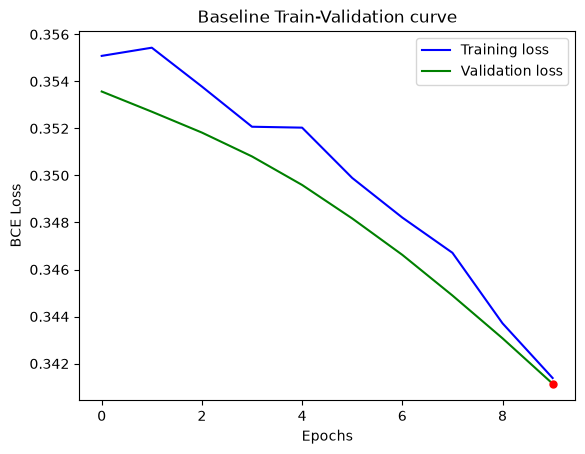

In [10]:
# Plotting the Graph
plt.plot(train_val_values.keys(), [y[0] for y in train_val_values.values()], color='blue', label='Training loss')
plt.plot(train_val_values.keys(), [y[1] for y in train_val_values.values()], color='green', label='Validation loss')
plt.plot(best_epoch, best_val_score, marker="o", markersize=5, color="red")
plt.title("Baseline Train-Validation curve")
plt.xlabel("Epochs")
plt.ylabel("BCE Loss")
plt.legend()
plt.show()

______________________________________________

## Experiment 1: experimenting with the global pooling layer

In [11]:
models_exp1 = []
pooling = 1
for i in range(3):
    models_exp1.append(PneumoniaCNNBaseline(adapt_pool = pooling))
    pooling += 1

loss = nn.BCEWithLogitsLoss(pos_weight = torch.tensor(zeros_count / ones_count))

# for AUC  curve plotting and caluculating
val_values = []
for _, y in val_loader:
    val_values.extend(y.tolist())
val_values = np.array([i[0] for i in val_values])

model1_performace = {i: [{}, 1, 0, np.array([])] for i in range(3)} # train_val_values, best_val_score, best_epoch, best_pred_val

In [12]:
#train_val_values = {} #1

#best_val_score, best_epoch = 1, 0 #2 , 3
#best_pred_val = np.array([]) #4

for i in model1_performace.keys():
    print(f'Experimenting the model with general pooling of size {i+1}x{i+1}')
    optimizer = torch.optim.SGD(models_exp1[i].parameters(), lr=0.01)
    temp_TV_Values = {}
    models_exp1[i] = models_exp1[i].to(device)
    for epoch in range(10):
        models_exp1[i].train()
        running_train, running_val = 0, 0
        for X, y in train_loader:
            X = X.to(device)
            y = y.float().to(device)
            pred = models_exp1[i](X)
            lossval = loss(pred, y)

            lossval.backward()
            optimizer.step()
            optimizer.zero_grad()
            running_train += lossval.item()

        avg_train_loss = running_train / len(train_loader)

        models_exp1[i].eval()
        running_val = 0
        val_pred_values_temp = []

        with torch.no_grad():

            for X_v, y_v in val_loader:
                X_v = X_v.to(device)
                y_v = y_v.float().to(device)
                pred = models_exp1[i](X_v)

                # save predictions
                val_pred_values_temp.append(pred)

                lossval = loss(pred, y_v)
                running_val += lossval.item()

        avg_val_loss = running_val / len(val_loader)
# train_val_values, best_val_score, best_epoch, best_pred_val
        if avg_val_loss < model1_performace[i][1] and avg_val_loss < avg_train_loss:

            model1_performace[i][2] = epoch
            model1_performace[i][1] = avg_val_loss

            model1_performace[i][3] = (
                torch.cat(val_pred_values_temp)
                .detach()
                .cpu()
                .numpy()
                .squeeze()
            )

        print(f"epoch {epoch}: avg train loss {running_train / len(train_loader):.4f} || avg validation loss {running_val / len(val_loader):.4f}")
        temp_TV_Values[epoch] = [(running_train / len(train_loader)), (running_val / len(val_loader))]
    model1_performace[i][0] = temp_TV_Values

Experimenting the model with general pooling of size 1x1
epoch 0: avg train loss 0.3569 || avg validation loss 0.3556
epoch 1: avg train loss 0.3562 || avg validation loss 0.3550
epoch 2: avg train loss 0.3561 || avg validation loss 0.3543
epoch 3: avg train loss 0.3548 || avg validation loss 0.3539
epoch 4: avg train loss 0.3549 || avg validation loss 0.3534
epoch 5: avg train loss 0.3544 || avg validation loss 0.3528
epoch 6: avg train loss 0.3537 || avg validation loss 0.3522
epoch 7: avg train loss 0.3536 || avg validation loss 0.3514
epoch 8: avg train loss 0.3512 || avg validation loss 0.3504
epoch 9: avg train loss 0.3507 || avg validation loss 0.3483
Experimenting the model with general pooling of size 2x2
epoch 0: avg train loss 0.3578 || avg validation loss 0.3557
epoch 1: avg train loss 0.3560 || avg validation loss 0.3546
epoch 2: avg train loss 0.3571 || avg validation loss 0.3534
epoch 3: avg train loss 0.3551 || avg validation loss 0.3519
epoch 4: avg train loss 0.3522 |

In [13]:
# Calculating the AUC of each model:
# train_val_values, best_val_score, best_epoch, best_pred_val

for i, j in model1_performace.items():
    fpr, tpr, thresholds = metrics.roc_curve(val_values, np.array(torch.tensor(model1_performace[i][3]).sigmoid()), pos_label=1)
    print(f'AUC value for the model with general pooling size of {i+1}x{i+1}: {metrics.auc(fpr, tpr)}')



AUC value for the model with general pooling size of 1x1: 0.7193563743692278
AUC value for the model with general pooling size of 2x2: 0.7823479005998286
AUC value for the model with general pooling size of 3x3: 0.7943063886508617


C:\Users\user1\AppData\Local\Temp\ipykernel_15148\3031786451.py:5: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  fpr, tpr, thresholds = metrics.roc_curve(val_values, np.array(torch.tensor(model1_performace[i][3]).sigmoid()), pos_label=1)
C:\Users\user1\AppData\Local\Temp\ipykernel_15148\3031786451.py:5: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  fpr, tpr, thresholds = metrics.roc_curve(val_values, np.array(torch.tensor(model1_performace[i][3]).sigmoid()), pos_label=1)
C:

C:\Users\user1\AppData\Local\Temp\ipykernel_15148\1005601099.py:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


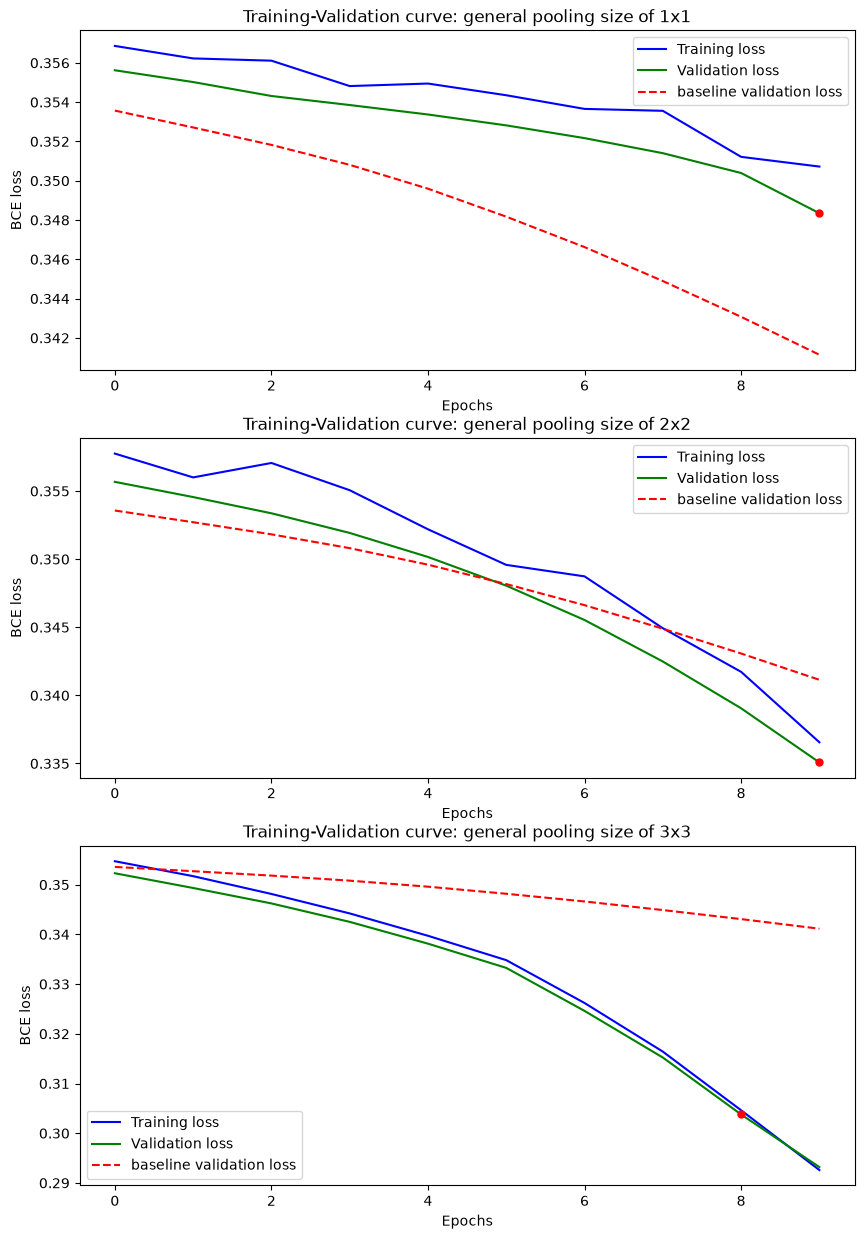

In [14]:
# Plottign the training, validation and baseline validation loss curves for each model

fig, axes = plt.subplots(3, 1, figsize=(10, 15))

for i, ax in enumerate(axes.flat):
    ax.plot(model1_performace[i][0].keys(), [y[0] for y in model1_performace[i][0].values()], color='blue', label='Training loss')
    ax.plot(model1_performace[i][0].keys(), [y[1] for y in model1_performace[i][0].values()], color='green', label='Validation loss')
    #ax.plot(model1_performace[i][0].keys(), [x[1]-y[1] for x, y in zip(train_val_values.values(), model1_performace[i][0].values())], color='red', label="Validation difference from baseline")
    ax.plot(train_val_values.keys(), [y[1] for y in train_val_values.values()], color='red', linestyle='--', label="baseline validation loss")
    ax.plot(model1_performace[i][2], model1_performace[i][1], marker="o", markersize=5, color="red")
    ax.set_title(f"Training-Validation curve: general pooling size of {i+1}x{i+1}")
    ax.set_xlabel("Epochs")
    ax.set_ylabel("BCE loss")
    ax.legend()
fig.show()
#ax.axis("off")

## Experiment 2: adding more epochs

In [15]:
model = PneumoniaCNNBaseline(adapt_pool = 3)
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
loss = nn.BCEWithLogitsLoss(pos_weight = torch.tensor(zeros_count / ones_count))

# for AUC  curve plotting and caluculating
val_values = []
for _, y in val_loader:
    val_values.extend(y.tolist())
val_values = np.array([i[0] for i in val_values])

In [16]:
train_val_values = {}

best_val_score, best_epoch = 1, 0
best_pred_val = np.array([])

model = model.to(device)

perf_per_ten_epoch = {}
checkpoint = 9

for epoch in range(100):
    model.train()
    running_train, running_val = 0, 0
    for X, y in train_loader:
        X = X.to(device)
        y = y.float().to(device)
        pred = model(X)
        lossval = loss(pred, y)

        lossval.backward()
        optimizer.step()
        optimizer.zero_grad()
        running_train += lossval.item()

    avg_train_loss = running_train / len(train_loader)

    model.eval()
    running_val = 0
    val_pred_values_temp = []

    with torch.no_grad():

        for X_v, y_v in val_loader:
            X_v = X_v.to(device)
            y_v = y_v.float().to(device)
            pred = model(X_v)

            # save predictions
            val_pred_values_temp.append(pred)

            lossval = loss(pred, y_v)
            running_val += lossval.item()

    avg_val_loss = running_val / len(val_loader)

    if avg_val_loss < best_val_score and avg_val_loss < avg_train_loss:

        best_epoch = epoch
        best_val_score = avg_val_loss

        best_pred_val = (
            torch.cat(val_pred_values_temp)
            .detach()
            .cpu()
            .numpy()
            .squeeze()
        )
    if epoch == checkpoint:
        perf_per_ten_epoch[checkpoint] = [(running_train / len(train_loader)), (running_val / len(val_loader))]
        checkpoint += 10
    print(f"epoch {epoch}: avg train loss {running_train / len(train_loader):.4f} || avg validation loss {running_val / len(val_loader):.4f}")
    train_val_values[epoch] = [(running_train / len(train_loader)), (running_val / len(val_loader))]

epoch 0: avg train loss 0.3547 || avg validation loss 0.3516
epoch 1: avg train loss 0.3524 || avg validation loss 0.3492
epoch 2: avg train loss 0.3487 || avg validation loss 0.3461
epoch 3: avg train loss 0.3447 || avg validation loss 0.3421
epoch 4: avg train loss 0.3389 || avg validation loss 0.3370
epoch 5: avg train loss 0.3335 || avg validation loss 0.3308
epoch 6: avg train loss 0.3248 || avg validation loss 0.3222
epoch 7: avg train loss 0.3148 || avg validation loss 0.3121
epoch 8: avg train loss 0.3029 || avg validation loss 0.3004
epoch 9: avg train loss 0.2887 || avg validation loss 0.2878
epoch 10: avg train loss 0.2741 || avg validation loss 0.2761
epoch 11: avg train loss 0.2624 || avg validation loss 0.2720
epoch 12: avg train loss 0.2484 || avg validation loss 0.2495
epoch 13: avg train loss 0.2333 || avg validation loss 0.2340
epoch 14: avg train loss 0.2159 || avg validation loss 0.2170
epoch 15: avg train loss 0.1956 || avg validation loss 0.2008
epoch 16: avg trai

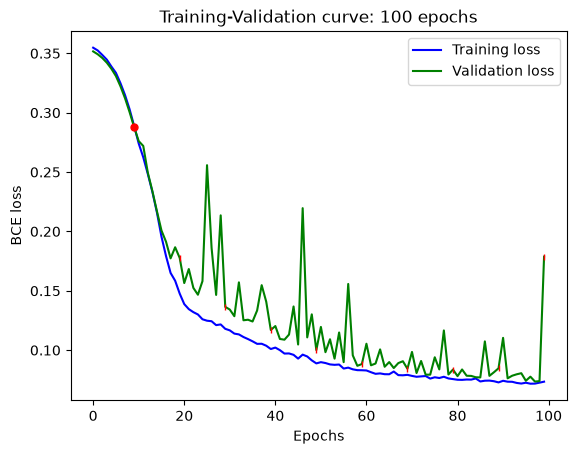

In [17]:
# Plotting the Graph
plt.plot(train_val_values.keys(), [y[0] for y in train_val_values.values()], color='blue', label='Training loss')
plt.plot(train_val_values.keys(), [y[1] for y in train_val_values.values()], color='green', label='Validation loss')
plt.plot(best_epoch, best_val_score, marker="o", markersize=5, color="red")
for i, j in perf_per_ten_epoch.items():
    plt.plot(i, j[1], marker="|", markersize=5, color="red")
plt.title("Training-Validation curve: 100 epochs")
plt.xlabel("Epochs")
plt.ylabel("BCE loss")
plt.legend()
plt.show()

In [18]:
fpr, tpr, thresholds = metrics.roc_curve(val_values, np.array(torch.tensor(best_pred_val).sigmoid()), pos_label=1)
metrics.auc(fpr, tpr)

C:\Users\user1\AppData\Local\Temp\ipykernel_15148\1939944690.py:1: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  fpr, tpr, thresholds = metrics.roc_curve(val_values, np.array(torch.tensor(best_pred_val).sigmoid()), pos_label=1)


0.8159763876987527

## Experiment 3: adding dropout and varying the rate

In [19]:
models_exp2 = []
pooling = 1
for i in [0, 0.25, 0.5]:
    models_exp2.append(PneumoniaCNNBaseline(3, i))
    pooling += 1

loss = nn.BCEWithLogitsLoss(pos_weight = torch.tensor(zeros_count / ones_count))

# for AUC  curve plotting and caluculating
val_values = []
for _, y in val_loader:
    val_values.extend(y.tolist())
val_values = np.array([i[0] for i in val_values])

model2_performace = {i: [{}, 1, 0, np.array([])] for i in range(3)} # train_val_values, best_val_score, best_epoch, best_pred_val

In [20]:
#train_val_values = {} #1

#best_val_score, best_epoch = 1, 0 #2 , 3
#best_pred_val = np.array([]) #4

for i in model2_performace.keys():
    print(f'Experimenting with model {i+1}')
    optimizer = torch.optim.SGD(models_exp2[i].parameters(), lr=0.01)
    temp_TV_Values = {}
    models_exp2[i] = models_exp2[i].to(device)
    for epoch in range(65):
        models_exp2[i].train()
        running_train, running_val = 0, 0
        for X, y in train_loader:
            X = X.to(device)
            y = y.float().to(device)
            pred = models_exp2[i](X)
            lossval = loss(pred, y)

            lossval.backward()
            optimizer.step()
            optimizer.zero_grad()
            running_train += lossval.item()

        avg_train_loss = running_train / len(train_loader)

        models_exp2[i].eval()
        running_val = 0
        val_pred_values_temp = []

        with torch.no_grad():

            for X_v, y_v in val_loader:
                X_v = X_v.to(device)
                y_v = y_v.float().to(device)
                pred = models_exp2[i](X_v)

                # save predictions
                val_pred_values_temp.append(pred)

                lossval = loss(pred, y_v)
                running_val += lossval.item()

        avg_val_loss = running_val / len(val_loader)
# train_val_values, best_val_score, best_epoch, best_pred_val
        if avg_val_loss < model2_performace[i][1] and avg_val_loss < avg_train_loss:

            model2_performace[i][2] = epoch
            model2_performace[i][1] = avg_val_loss

            model2_performace[i][3] = (
                torch.cat(val_pred_values_temp)
                .detach()
                .cpu()
                .numpy()
                .squeeze()
            )

        print(f"epoch {epoch}: avg train loss {running_train / len(train_loader):.4f} || avg validation loss {running_val / len(val_loader):.4f}")
        temp_TV_Values[epoch] = [(running_train / len(train_loader)), (running_val / len(val_loader))]
    model2_performace[i][0] = temp_TV_Values

Experimenting with model 1
epoch 0: avg train loss 0.3560 || avg validation loss 0.3529
epoch 1: avg train loss 0.3525 || avg validation loss 0.3507
epoch 2: avg train loss 0.3510 || avg validation loss 0.3478
epoch 3: avg train loss 0.3471 || avg validation loss 0.3437
epoch 4: avg train loss 0.3417 || avg validation loss 0.3392
epoch 5: avg train loss 0.3374 || avg validation loss 0.3341
epoch 6: avg train loss 0.3294 || avg validation loss 0.3272
epoch 7: avg train loss 0.3219 || avg validation loss 0.3188
epoch 8: avg train loss 0.3119 || avg validation loss 0.3092
epoch 9: avg train loss 0.3014 || avg validation loss 0.3001
epoch 10: avg train loss 0.2922 || avg validation loss 0.2915
epoch 11: avg train loss 0.2841 || avg validation loss 0.2878
epoch 12: avg train loss 0.2786 || avg validation loss 0.2818
epoch 13: avg train loss 0.2733 || avg validation loss 0.2762
epoch 14: avg train loss 0.2710 || avg validation loss 0.2736
epoch 15: avg train loss 0.2638 || avg validation los

C:\Users\user1\AppData\Local\Temp\ipykernel_15148\2099728070.py:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


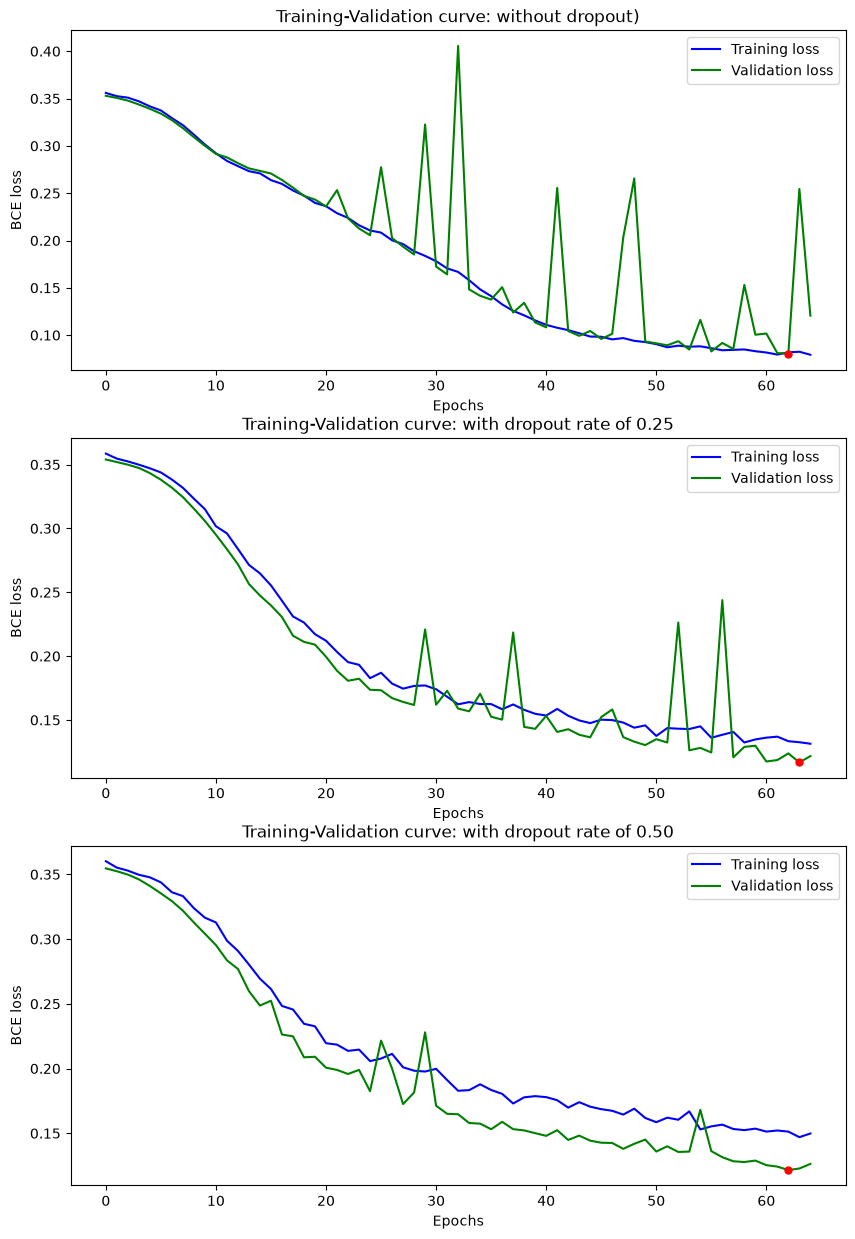

In [21]:
fig, axes = plt.subplots(3, 1, figsize=(10, 15))
axes[0].set_title(f"Training-Validation curve: without dropout)")
axes[1].set_title(f"Training-Validation curve: with dropout rate of 0.25")
axes[2].set_title(f"Training-Validation curve: with dropout rate of 0.50")

for i, ax in enumerate(axes.flat):
    ax.plot(model2_performace[i][0].keys(), [y[0] for y in model2_performace[i][0].values()], color='blue', label='Training loss')
    ax.plot(model2_performace[i][0].keys(), [y[1] for y in model2_performace[i][0].values()], color='green', label='Validation loss')
    #ax.plot(model1_performace[i][0].keys(), [x[1]-y[1] for x, y in zip(train_val_values.values(), model1_performace[i][0].values())], color='red', label="Validation difference from baseline")
    #ax.plot(train_val_values.keys(), [y[1] for y in train_val_values.values()], color='red', linestyle='--', label="baseline validation loss")
    ax.plot(model2_performace[i][2], model2_performace[i][1], marker="o", markersize=5, color="red")
    ax.set_xlabel("Epochs")
    ax.set_ylabel("BCE loss")
    ax.legend()
fig.show()

From the experiments, using a larger adaptive pooling size (3×3 in this case) slightly improved the model performance. The improvement was relatively small and could be considered negligible, although a modest benefit was still observed.  
Increasing the number of training epochs resulted in a progressive decrease in the loss. However, the rate of improvement slowed down from approximately the 33rd epoch onward. At the same time, the validation loss showed larger fluctuations, indicating that the model performance became less stable during further training.  
The no-dropout model achieved the lowest loss but showed substantial fluctuations in validation performance. Introducing a dropout rate of 0.25 considerably improved validation stability while maintaining low loss values. Increasing the dropout rate to 0.5 further smoothed the validation curve, but at the expense of slower convergence and higher final losses. Therefore, a dropout rate of 0.25 provided the best compromise between model performance and stability.

For experimenting with Explainable AI, the model with a 3x3 adaptative pooling size, a dropout rate of 0.25 and 65 epochs would be chosen.

## XAI implementation: Grad-CAM

In [22]:
model = PneumoniaCNNBaseline(3, 0.25)
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
loss = nn.BCEWithLogitsLoss(pos_weight = torch.tensor(zeros_count / ones_count))

In [23]:
train_val_values = {}

best_val_score, best_epoch = 1, 0
best_pred_val = np.array([])

model = model.to(device)
best_model = model

for epoch in range(60):
    model.train()
    running_train, running_val = 0, 0
    for X, y in train_loader:
        X = X.to(device)
        y = y.float().to(device)
        pred = model(X)
        lossval = loss(pred, y)

        lossval.backward()
        optimizer.step()
        optimizer.zero_grad()
        running_train += lossval.item()

    avg_train_loss = running_train / len(train_loader)

    model.eval()
    running_val = 0
    val_pred_values_temp = []

    with torch.no_grad():

        for X_v, y_v in val_loader:
            X_v = X_v.to(device)
            y_v = y_v.float().to(device)
            pred = model(X_v)

            # save predictions
            val_pred_values_temp.append(pred)

            lossval = loss(pred, y_v.float())
            running_val += lossval.item()

    avg_val_loss = running_val / len(val_loader)

    if avg_val_loss < best_val_score and avg_val_loss < avg_train_loss:

        best_epoch = epoch
        best_val_score = avg_val_loss

        best_model = copy.deepcopy(model)
        print(f"------- model at epoch {epoch} have been picked -------")

        best_pred_val = (
            torch.cat(val_pred_values_temp)
            .detach()
            .cpu()
            .numpy()
            .squeeze()
        )

    print(f"epoch {epoch}: avg train loss {running_train / len(train_loader):.4f} || avg validation loss {running_val / len(val_loader):.4f}")
    train_val_values[epoch] = [(running_train / len(train_loader)), (running_val / len(val_loader))]

------- model at epoch 0 have been picked -------
epoch 0: avg train loss 0.3570 || avg validation loss 0.3510
------- model at epoch 1 have been picked -------
epoch 1: avg train loss 0.3517 || avg validation loss 0.3469
------- model at epoch 2 have been picked -------
epoch 2: avg train loss 0.3465 || avg validation loss 0.3421
------- model at epoch 3 have been picked -------
epoch 3: avg train loss 0.3428 || avg validation loss 0.3370
------- model at epoch 4 have been picked -------
epoch 4: avg train loss 0.3356 || avg validation loss 0.3304
------- model at epoch 5 have been picked -------
epoch 5: avg train loss 0.3297 || avg validation loss 0.3221
------- model at epoch 6 have been picked -------
epoch 6: avg train loss 0.3199 || avg validation loss 0.3117
------- model at epoch 7 have been picked -------
epoch 7: avg train loss 0.3089 || avg validation loss 0.3000
------- model at epoch 8 have been picked -------
epoch 8: avg train loss 0.2957 || avg validation loss 0.2872
-

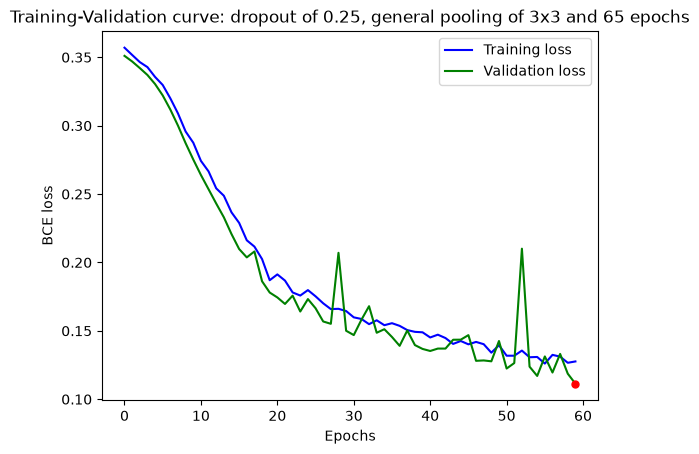

In [24]:
# Plotting the Graph
plt.plot(train_val_values.keys(), [y[0] for y in train_val_values.values()], color='blue', label='Training loss')
plt.plot(train_val_values.keys(), [y[1] for y in train_val_values.values()], color='green', label='Validation loss')
plt.plot(best_epoch, best_val_score, marker="o", markersize=5, color="red")
plt.title("Training-Validation curve: dropout of 0.25, general pooling of 3x3 and 65 epochs")
plt.xlabel("Epochs")
plt.ylabel("BCE loss")
plt.legend()
plt.show()

In [25]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import BinaryClassifierOutputTarget

In [26]:
best_model.eval()
target_layer = best_model.features[3]
cam = GradCAM(
    model=best_model,
    target_layers=[target_layer]
)

In [27]:
print(best_model)

PneumoniaCNNBaseline(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Dropout2d(p=0.25, inplace=False)
  )
  (pool): AdaptiveAvgPool2d(output_size=(3, 3))
  (hidden1): Linear(in_features=288, out_features=16, bias=True)
  (relu): ReLU()
  (drop): Dropout(p=0.25, inplace=False)
  (output): Linear(in_features=16, out_features=1, bias=True)
)


### Grad-CAM for Pneumonia Prediction

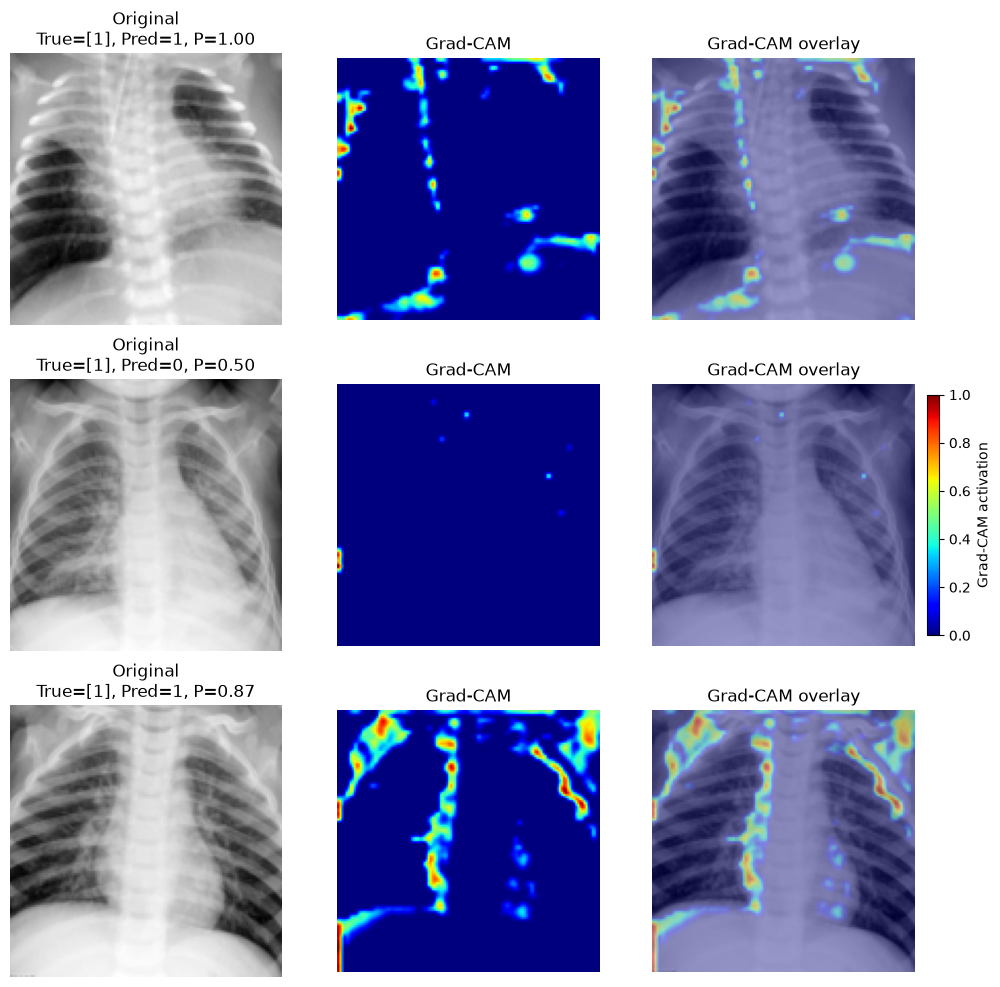

In [28]:
# Pick 3 pneumonia images
test_images = random.sample(
    [(image, label) for image, label in test_dataset if label == 1],
    3
)

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for i, (image, label) in enumerate(test_images):

    # Add batch dimension
    input_tensor = image.unsqueeze(0).to(device)

    # Prediction
    with torch.no_grad():
        logit = best_model(input_tensor)
        prob = torch.sigmoid(logit).item()
        pred = int(prob >= 0.5)

    # Grad-CAM for pneumonia class
    targets = [BinaryClassifierOutputTarget(1)]

    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=targets
    )[0]

    # ---- Undo normalization for visualization ----
    img = image.squeeze().cpu().numpy()
    #[0.5716654658317566], [0.1761743128299713]
    mean = 0.5716654658317566   # replace with your actual normalization mean
    std = 0.1761743128299713    # replace with your actual normalization std

    img = img * std + mean
    img = img.clip(0, 1)

    # ---- Original ----
    axes[i, 0].imshow(img, cmap="gray")
    axes[i, 0].set_title(
        f"Original\nTrue={label}, Pred={pred}, P={prob:.2f}"
    )
    axes[i, 0].axis("off")

    # ---- Grad-CAM ----
    im = axes[i, 1].imshow(
        grayscale_cam,
        cmap="jet",
        vmin=0,
        vmax=1
    )
    axes[i, 1].set_title("Grad-CAM")
    axes[i, 1].axis("off")

    # ---- Overlay ----
    axes[i, 2].imshow(img, cmap="gray")
    axes[i, 2].imshow(
        grayscale_cam,
        cmap="jet",
        alpha=0.4,
        vmin=0,
        vmax=1
    )
    axes[i, 2].set_title("Grad-CAM overlay")
    axes[i, 2].axis("off")


# One colorbar for all CAM images
cbar = fig.colorbar(
    im,
    ax=axes[:, 1:].ravel().tolist(),
    fraction=0.02,
    pad=0.02
)

cbar.set_label("Grad-CAM activation")

plt.show()

so basically from what I understand from this model, sometimes it examines lung regions and sometimes it focuses on the thorax and sometimes outside the patient's body

### Grad-CAM for normal lung prediction

In [29]:
test_image = random.sample(
    [(image, idx) for image, idx in test_dataset if idx == 0],
    1
)[0]

targets = [BinaryClassifierOutputTarget(0)]

image, label = test_image
input_tensor = image.unsqueeze(0).to(device)

with torch.no_grad():
    logit = best_model(input_tensor)
    probability = torch.sigmoid(logit)

predicted_class = (probability >= 0.5).int()

print("True label:", label)
print("Raw output (logit):", logit.item())
print("Probability of class 0:", probability.item())
print("Predicted class:", predicted_class.item())

grayscale_cam = cam(
    input_tensor=input_tensor,
    targets=targets
)[0]

True label: [0]
Raw output (logit): -1.4775075912475586
Probability of class 0: 0.18580417335033417
Predicted class: 0


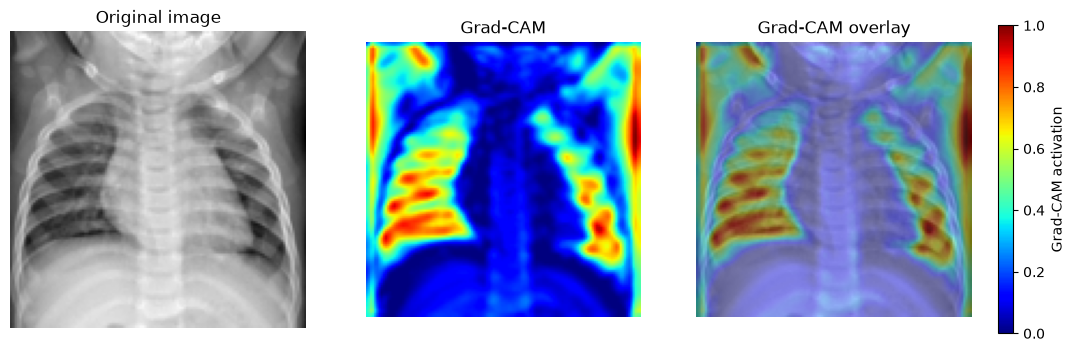

In [30]:
img = image.squeeze().cpu().numpy()
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

# Original image
axes[0].imshow(img, cmap="gray")
axes[0].set_title("Original image")
axes[0].axis("off")

# Grad-CAM only
im = axes[1].imshow(
    grayscale_cam,
    cmap="jet",
    vmin=0,
    vmax=1
)
axes[1].set_title("Grad-CAM")
axes[1].axis("off")

# Overlay
axes[2].imshow(img, cmap="gray")
overlay = axes[2].imshow(
    grayscale_cam,
    cmap="jet",
    alpha=0.4,
    vmin=0,
    vmax=1
)
axes[2].set_title("Grad-CAM overlay")
axes[2].axis("off")

# Shared color scale for Grad-CAM
cbar = fig.colorbar(
    im,
    ax=[axes[1], axes[2]],
    fraction=0.03,
    pad=0.04
)
cbar.set_label("Grad-CAM activation")

plt.show()

_____________________